Import Library

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import summary_table
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import shapiro, levene
from scipy.stats import levene
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Import Data

In [ ]:
data = pd.read_excel('Data_New.xlsx')
data.head()

,Kota/Kabupaten,Tahun,Jumlah Penduduk,Jumlah SD,Jumlah Penduduk Miskin,Angka Buta Huruf
0,KABUPATEN BOGOR,2017,4358,1411,487.3,22.0
1,KABUPATEN SUKABUMI,2017,2537,947,197.1,4.0
2,KABUPATEN CIANJUR,2017,225,1086,257.4,6.0
3,KABUPATEN BANDUNG,2017,3525,1801,268.0,12.0
4,KABUPATEN GARUT,2017,2222,651,291.2,10.0


In [ ]:
data.shape

(189, 6)

Statistika Deskriptif

In [ ]:
data.describe()

,Tahun,Jumlah Penduduk,Jumlah SD,Jumlah Penduduk Miskin,Angka Buta Huruf
count,189.000000,189.000000,189.000000,189.000000,189.000000
mean,2020.000000,1712.142857,726.645503,144.230688,23.610582
std,2.005312,1112.140980,458.348906,97.752164,34.562898
min,2017.000000,101.000000,86.000000,10.100000,0.000000
25%,2018.000000,936.000000,284.000000,75.900000,3.000000
50%,2020.000000,1650.000000,673.000000,136.000000,9.000000
75%,2022.000000,2438.000000,974.000000,199.900000,25.000000
max,2023.000000,5559.000000,1903.000000,491.200000,173.000000


Cek data yang tidak punya nilai

In [ ]:
data.isnull().sum()

,0
Kota/Kabupaten,0
Tahun,0
Jumlah Penduduk,0
Jumlah SD,0
Jumlah Penduduk Miskin,0
Angka Buta Huruf,0


Menghapus Kolom Kota/Kabupaten dan Tahun

In [ ]:
df = data.copy()
df = df.drop(columns=['Kota/Kabupaten','Tahun'])
df.head()

,Jumlah Penduduk,Jumlah SD,Jumlah Penduduk Miskin,Angka Buta Huruf
0,4358,1411,487.3,22.0
1,2537,947,197.1,4.0
2,225,1086,257.4,6.0
3,3525,1801,268.0,12.0
4,2222,651,291.2,10.0


Visualisasi Faktor Terhadap Angka Buta Huruf

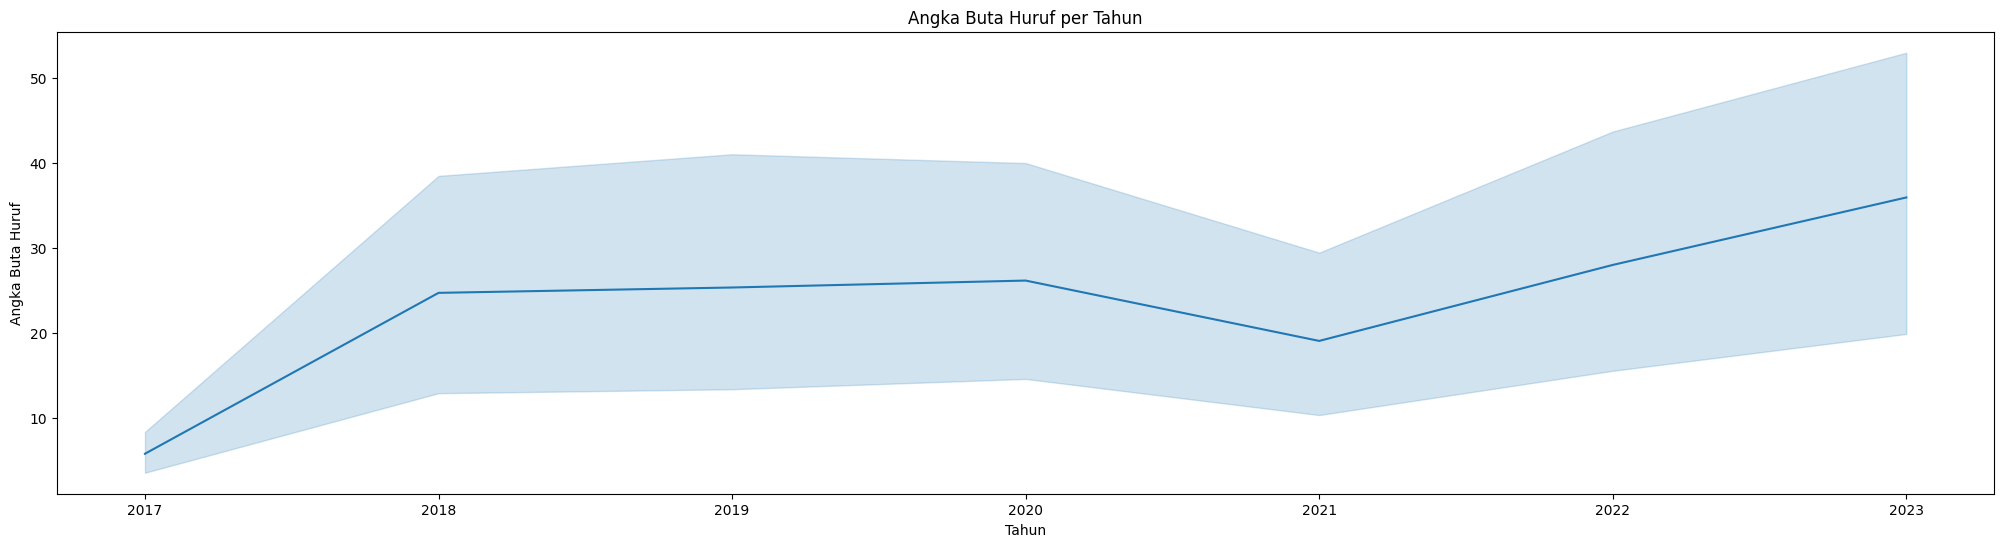

In [ ]:
# Visualisasi Angka Buta Huruf per Tahun
plt.figure(figsize=(25,6))
sns.lineplot(x = data['Tahun'], y = data['Angka Buta Huruf'],data=data)
plt.title('Angka Buta Huruf per Tahun')
plt.show()

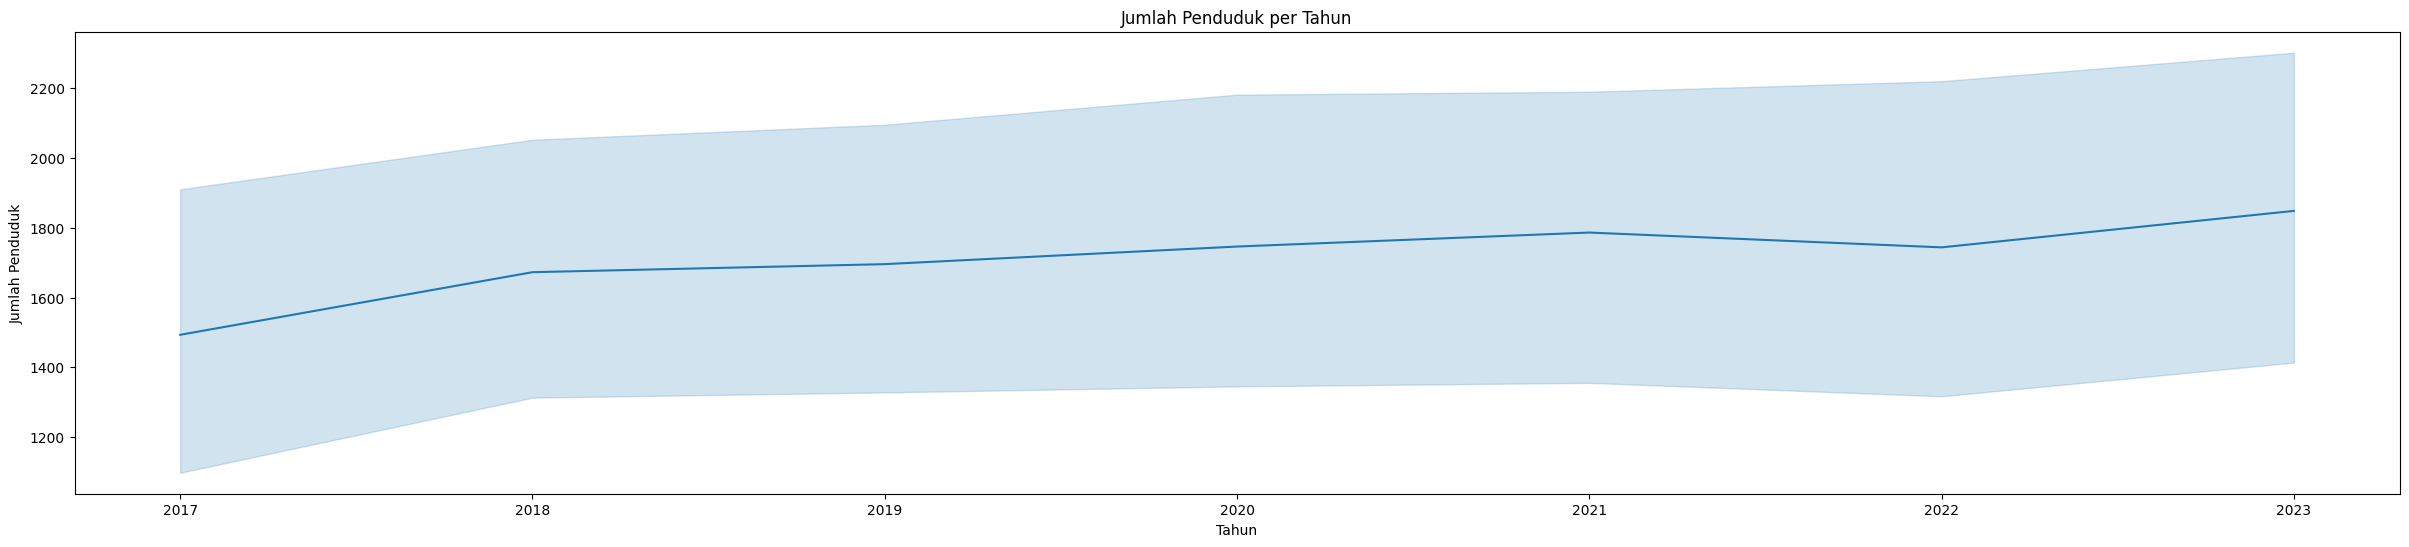

In [ ]:
# Visualisasi Jumlah Penduduk per Tahun
plt.figure(figsize=(30,6))
sns.lineplot(x = data['Tahun'], y = data['Jumlah Penduduk'],data=data)
plt.title('Jumlah Penduduk per Tahun')
plt.show()

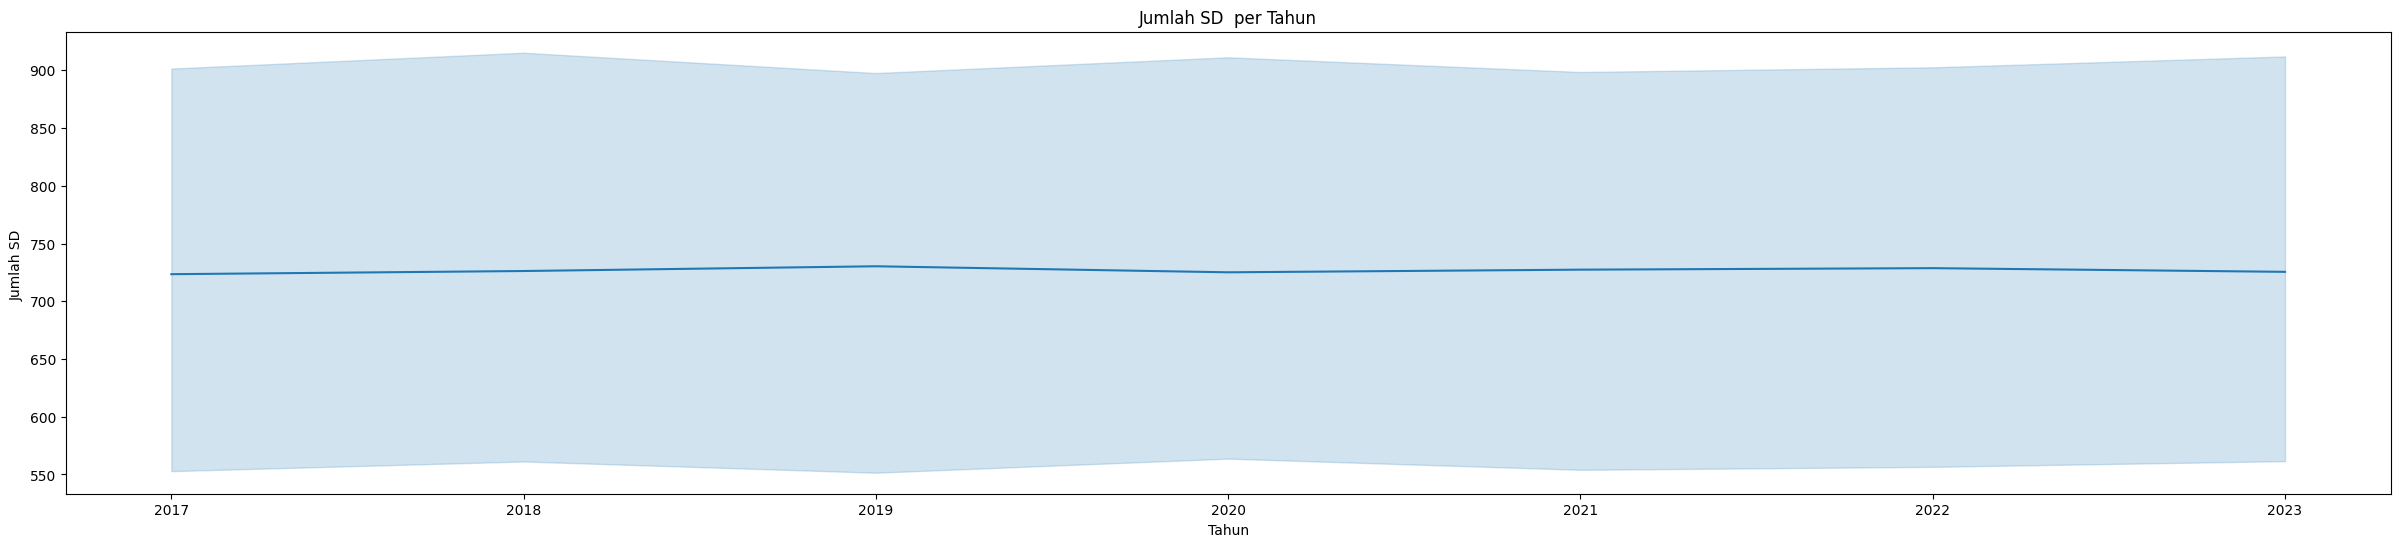

In [ ]:
# Visualisasi Jumlah SD  per Tahun
plt.figure(figsize=(30,6))
sns.lineplot(x = data['Tahun'], y = data['Jumlah SD '],data=data)
plt.title('Jumlah SD  per Tahun')
plt.show()

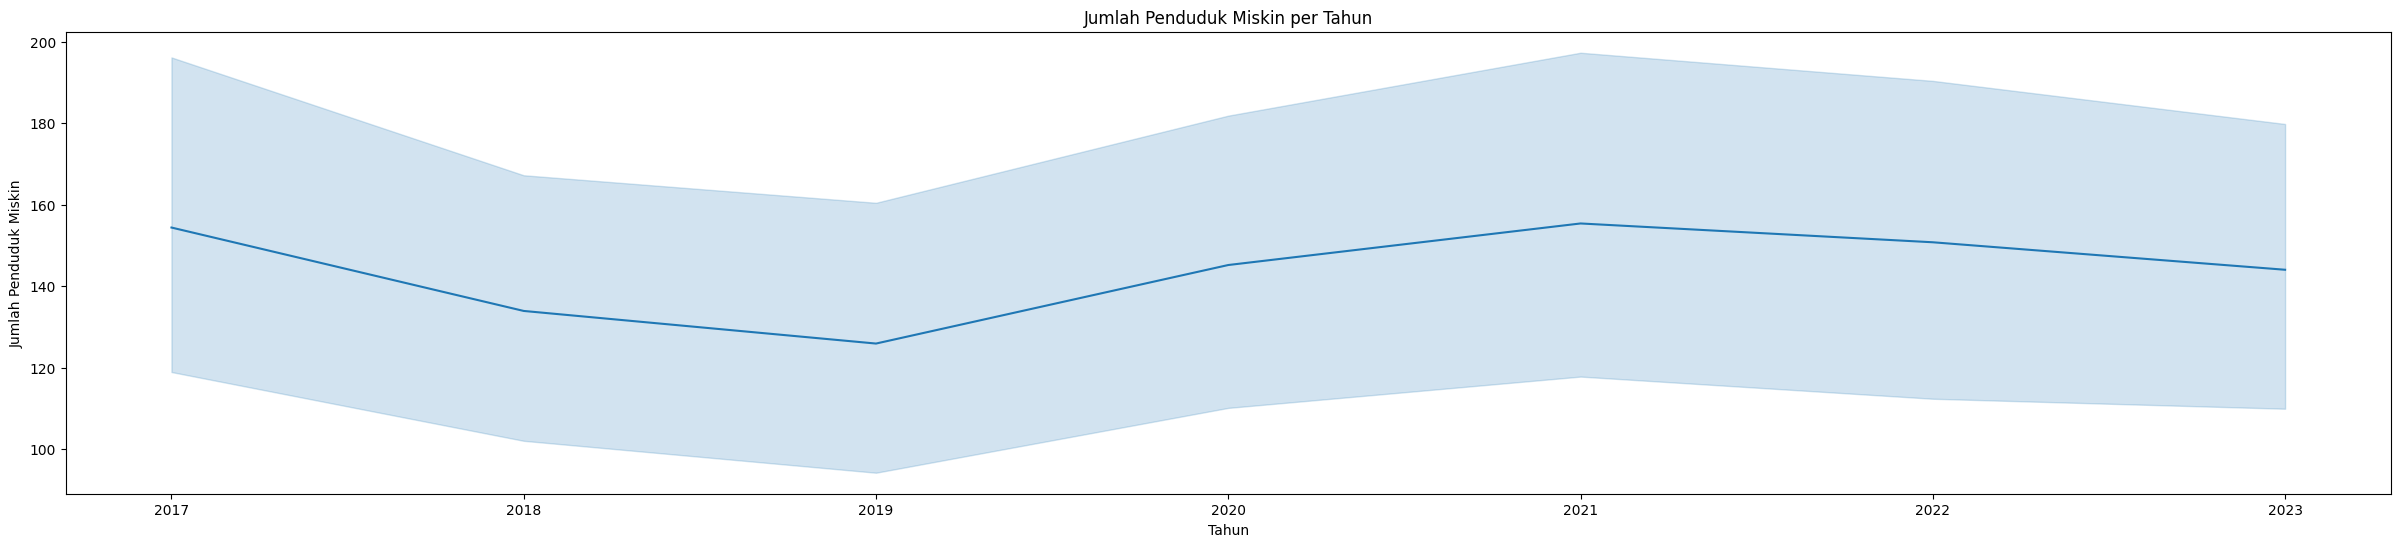

In [ ]:
# Visualisasi Jumlah Penduduk Miskin per Tahun
plt.figure(figsize=(30,6))
sns.lineplot(x = data['Tahun'], y = data['Jumlah Penduduk Miskin'])
plt.title('Jumlah Penduduk Miskin per Tahun')
plt.show()

Korelasi Variabel

In [ ]:
df.corr()

,Jumlah Penduduk,Jumlah SD,Jumlah Penduduk Miskin,Angka Buta Huruf
Jumlah Penduduk,1.000000,0.762884,0.850534,0.423331
Jumlah SD,0.762884,1.000000,0.844751,0.364254
Jumlah Penduduk Miskin,0.850534,0.844751,1.000000,0.510503
Angka Buta Huruf,0.423331,0.364254,0.510503,1.000000


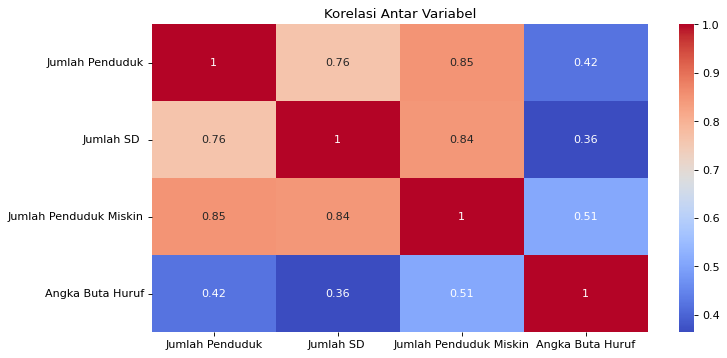

In [ ]:
fig, ax = plt.subplots(figsize=(10,5), dpi=80)
sns.heatmap(df.loc[:, 'Jumlah Penduduk':'Angka Buta Huruf'].corr(), cmap='coolwarm', annot=True)
plt.title('Korelasi Antar Variabel')
plt.show()

MODEL PREDIKSI ANGKA BUTA HURUF

Mencari Random State Dengan Nilai r2 score terbaik

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

x = df.drop(columns='Angka Buta Huruf')
y = df['Angka Buta Huruf']

# Inisialisasi variabel untuk menyimpan hasil terbaik
best_random_state = None
best_r2_score = -float('inf')  # Inisialisasi dengan nilai R^2 yang sangat rendah agar dapat diperbarui

# Coba beberapa nilai random_state dan evaluasi performa model
for random_state in range(5000):  # Lakukan percobaan untuk beberapa nilai random_state
    # Bagi data menggunakan nilai random_state saat ini
    X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=random_state)

    # Bangun model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Lakukan prediksi
    y_pred = model.predict(X_test)

    # Hitung R^2 score
    r2 = r2_score(y_test, y_pred)

    # Perbarui nilai random_state terbaik jika R^2 score saat ini lebih baik
    if r2 > best_r2_score:
        best_random_state = random_state
        best_r2_score = r2

# Cetak nilai random_state terbaik
print("Best random_state:", best_random_state)
print(best_r2_score)

Best random_state: 3980
0.6443514214294263


REGRES LINEAR BERGANDA

Train and Test Split

In [ ]:
x = df.drop(columns='Angka Buta Huruf')
y = df[['Angka Buta Huruf']]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = best_random_state)
model_reg = LinearRegression()
model_reg.fit(x_train, y_train)

LinearRegression()

EVALUASI

In [ ]:
y_pred = model_reg.predict(x_test)
print(y_pred[:5])
print(y_test.head())

#R Squared
print(f'R Squared : {r2_score(y_test, y_pred)}')
#MAE
print(f'MAE : {mean_absolute_error(y_test, y_pred)}')
#MSE
print(f'MSE : {mean_squared_error(y_test, y_pred)}')

[[ 5.93459305]
 [13.5854298 ]
 [32.70570655]
 [48.10780341]
 [18.88568114]]
     Angka Buta Huruf
125               3.0
74               10.0
97                6.0
14               12.0
171              45.0
R Squared : 0.6443514214294263
MAE : 11.02327323015212
MSE : 268.47457030102254


In [ ]:
# Print the coefficients
print('Coefficients:')
print('Intercept :', model_reg.intercept_)
print('Koefisien :', model_reg.coef_)



Coefficients:
Intercept : [1.83733452]
Koefisien : [[ 9.55991635e-06 -2.03812876e-02  2.52721349e-01]]


MODEL PREDIKSI FAKTOR (VARIABEL BEBAS)

In [ ]:
#import data
data2 = pd.read_excel("Data_Rata-Rata_Pertahun.xlsx")
data2.reset_index(drop=True, inplace=True)
df1 = data2.copy()
df1 = df1.drop(columns=['Angka Buta Huruf'])
df1.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Data_Rata-Rata_Pertahun.xlsx'

Prediksi Faktor hingga 2026


In [ ]:
# Import library
from prophet import Prophet

In [ ]:
# Definisikan kolom yang akan diprediksi
columns_to_forecast = ['Jumlah Penduduk', 'Jumlah SD ', 'Jumlah Penduduk Miskin']

# Buat DataFrame kosong untuk menampung hasil prediksi
forecasted_df = pd.DataFrame()

# Prediksi setiap kolom dan masukkan ke dalam DataFrame
for column in columns_to_forecast:
  # Membangun model forecasting
  model = Prophet(interval_width=0.95)

  # Mengganti nama kolom untuk prediksi
  df_prophet = df1[['Tahun', column]].rename(columns={'Tahun': 'ds', column: 'y'})

  # Melatih model
  model.fit(df_prophet)

  # Menentukan tanggal prediksi
  future_dates = pd.date_range(start='2024-01-01', periods=3, freq='y')
  future_df = pd.DataFrame({'ds': future_dates})

  # Prediksi nilai faktor-faktor
  forecast = model.predict(future_df)
  forecasted_values = forecast[['yhat']]

  # Mengubah kembali nama kolom
  forecasted_values.rename(columns={'yhat': column}, inplace=True)

  # Memasukkan kolom prediksi ke dalam DataFrame
  forecasted_df = pd.concat([forecasted_df, forecasted_values], axis=1)

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:n_changepoints greater than number of observations. Using 4.
DEBUG:cmdstanpy:input tempfile: /tmp/tmps04oneog/_enyp1jz.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmps04oneog/msy46wn8.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.10/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=98161', 'data', 'file=/tmp/tmps04oneog/_enyp1jz.json', 'init=/tmp/tmps04oneog/msy46wn8.json', 'output', 'file=/tmp/tmps04oneog/prophet_modelrbwd05u5/prophet_model-20240731095401.csv', 'method=optimize', 'algorithm=newton', 'iter=10000']
09:54:01 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
09:54:01 - cmdstanpy - INFO - Chain [1] done processing
INFO:c

In [ ]:
print(forecasted_df)

   Jumlah Penduduk  Jumlah SD   Jumlah Penduduk Miskin
0      1978.341444  502.448016              148.008266
1      2034.471578  413.235875              154.442182
2      2087.845289  317.100631              164.236647


##Prediksi 2024-2026


In [ ]:
future_df = model_reg.predict(forecasted_df)
tahun = [2024,2025,2026]
df_tahun = pd.DataFrame(tahun, columns=['Tahun'])
df_future = pd.DataFrame(future_df, columns=['Angka Buta Huruf'])
df_3yr = pd.concat([df_tahun, df_future], axis=1)
df_3yr

,Tahun,Angka Buta Huruf
0,2024,29.020558
1,2025,32.465341
2,2026,36.900482


In [ ]:
# Menggabung data prediksi faktor ke data prediksi Angka Buta Huruf
data_future = pd.concat([df_3yr,forecasted_df], axis=1)
# Menggabung data prediksi ke data awal
data_final = pd.concat([data2,data_future], axis=0)
# Reset index
data_final.reset_index(drop=True, inplace=True)
# Menampilkan 7 data terakhir
data_final.tail(7)

,Tahun,Jumlah Penduduk,Jumlah SD,Jumlah Penduduk Miskin,Angka Buta Huruf
3,2020,1745.962963,725.074074,145.192593,26.196296
4,2021,1786.037037,727.370370,155.396296,19.103704
5,2022,1743.629630,728.666667,150.777778,28.033333
6,2023,1848.074074,725.481481,144.029630,35.962963
7,2024,1978.341444,502.448016,148.008266,29.020558
8,2025,2034.471578,413.235875,154.442182,32.465341
9,2026,2087.845289,317.100631,164.236647,36.900482


##Visualisasi Angka Buta Huruf dari Tahun ke Tahun

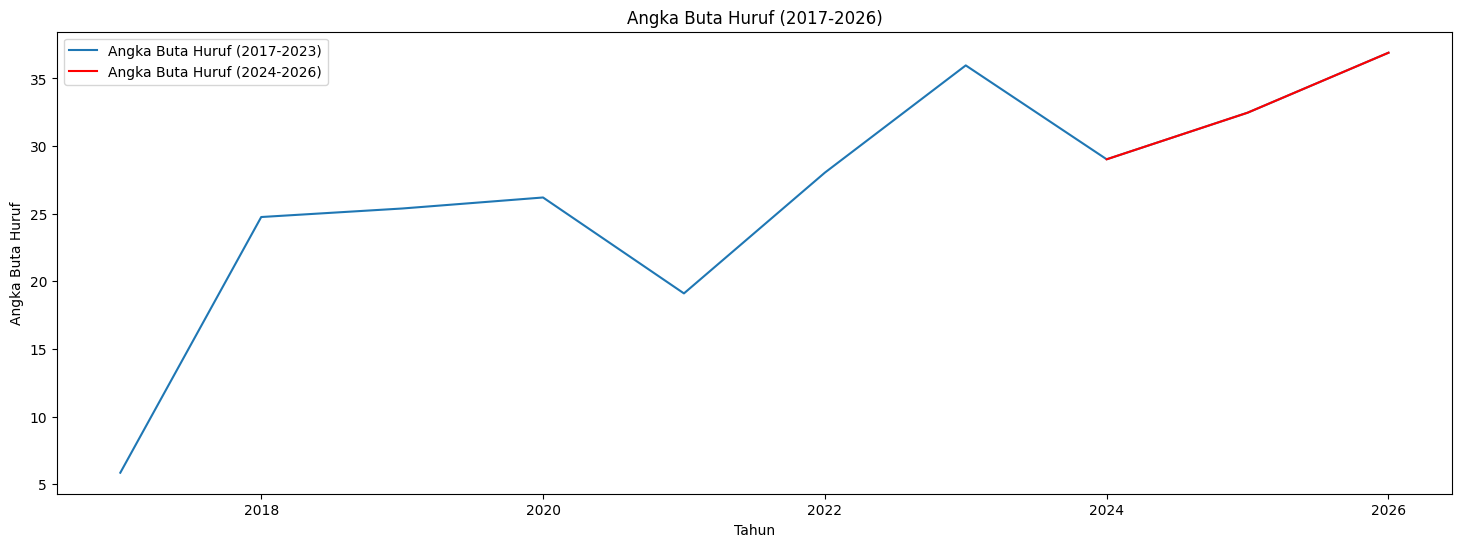

In [ ]:
# DataFrame Tahun 2024-2026
future_df = data_final[data_final['Tahun'] >= 2024]

# Membangun grafik garis
plt.figure(figsize=(18, 6))
plt.plot(data_final['Tahun'], data_final['Angka Buta Huruf'], label='Angka Buta Huruf (2017-2023)')
plt.plot(future_df['Tahun'], future_df['Angka Buta Huruf'], color='red', label='Angka Buta Huruf (2024-2026)')

# Membuat label dan judul
plt.xlabel('Tahun')
plt.ylabel('Angka Buta Huruf')
plt.title('Angka Buta Huruf (2017-2026)')

# Menampilkan grafik dan keterangaan
plt.legend()
plt.show()